# Reading MED (Salome / code_aster) meshes with pyramids-mesh

The **MED** format is the native mesh-and-field container of the [Salome](https://www.salome-platform.org/) platform and the [code_aster](https://code-aster.org/) finite-element solver. Like CGNS it is built on **HDF5**.

`driver="med"` forces the HDF5 reader. A MED mesh lives in the model's own coordinate frame — no projection — so pyramids-mesh reports **`crs=None`**.

We use `cylinder.med`, a small mixed triangle+quadrilateral surface written by Salome 9.2.2.

> Source: meshio test suite (`tests/meshes/med/`), MIT.

## Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [1]:
import numpy as np
import geopandas as gpd
from pathlib import Path
from pyramids.netcdf.ugrid import UgridDataset

DATA = Path("../../examples/data")  # resolved relative to THIS notebook
DATA
import matplotlib.pyplot as plt

## Quickstart: read the MED file

`driver="med"` forces the HDF5 path, the same multidimensional driver used for CGNS.

The one rule that matters: **pass a `pathlib.Path`, never a `str`** — `read_file` keys its driver dispatch off the `Path` type. `UgridDataset.read_file(...)` returns a `UgridDataset`, the in-memory UGRID container every pyramids-mesh driver produces.

In [2]:
ds = UgridDataset.read_file(DATA / "med" / "cylinder.med", driver="med")
ds

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 7 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 8 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


UgridDataset(mesh='mesh2d', n_node=33, n_face=22, n_edge=0, variables=['node_z'])

In [3]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

## What did we get?

A few scalar properties describe the dataset at a glance: node and face counts, the coordinate reference system, and the planar bounding box.

In [4]:
print("n_node :", ds.n_node)
print("n_face :", ds.n_face)
print("crs    :", ds.crs)
print("epsg   :", ds.epsg)
print("data   :", ds.data_variable_names)
print("bounds :", ds.bounds)

n_node : 33
n_face : 22
crs    : None
epsg   : None
data   : ['node_z']
bounds : (-1.0, -1.0, 1.0, 1.0)


`crs`/`epsg` are `None`. The mesh is small — 33 nodes, ~22 faces — and spans the `[-1, 1]` square, the footprint of a cylinder cross-section. It carries a `node_z` variable.

### Summary table

`ds.summary()` returns a pandas `DataFrame` with per-variable statistics (count / min / max / mean / std). It reports `node_z` here.

In [5]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
node_z,33,0.0,1.0,0.496902,0.408536


## The mesh geometry

`ds.mesh` is a `Mesh2d`: node coordinates plus the **face-node connectivity**, an `(n_face, k)` integer table where `k` is the largest number of nodes any face has. Triangles fill 3 columns; quadrilaterals fill 4 (a shorter face pads the spare slot). `face_areas` and `face_centroids` are derived on demand.

In [6]:
mesh = ds.mesh
fnc = mesh.face_node_connectivity.data
areas = np.asarray(mesh.face_areas)
cent = np.asarray(mesh.face_centroids)       # shape (2, n_face)
print("mesh type         :", type(mesh).__name__)
print("connectivity shape:", fnc.shape)
print("node_x range      :", float(mesh.node_x.min()), "->", float(mesh.node_x.max()))
print("node_y range      :", float(mesh.node_y.min()), "->", float(mesh.node_y.max()))
print("face_areas        :", float(areas.min()), "->", float(areas.max()))
print("centroids shape   :", cent.shape)

mesh type         : Mesh2d
connectivity shape: (22, 4)
node_x range      : -1.0 -> 1.0
node_y range      : -1.0 -> 1.0
face_areas        : 0.0 -> 0.6293922400695287
centroids shape   : (2, 22)


The connectivity has **4 columns**, but this is a *mixed* mesh: triangles use three slots and pad the fourth, while quads use all four. The spread of `face_areas` (some cells much smaller than others) reflects that mix.

## Wireframe

`plot_outline()` draws the bare mesh edges — the quickest way to eyeball the topology and the element shapes before colouring anything.

Text(0.5, 1.0, 'MED mesh outline')

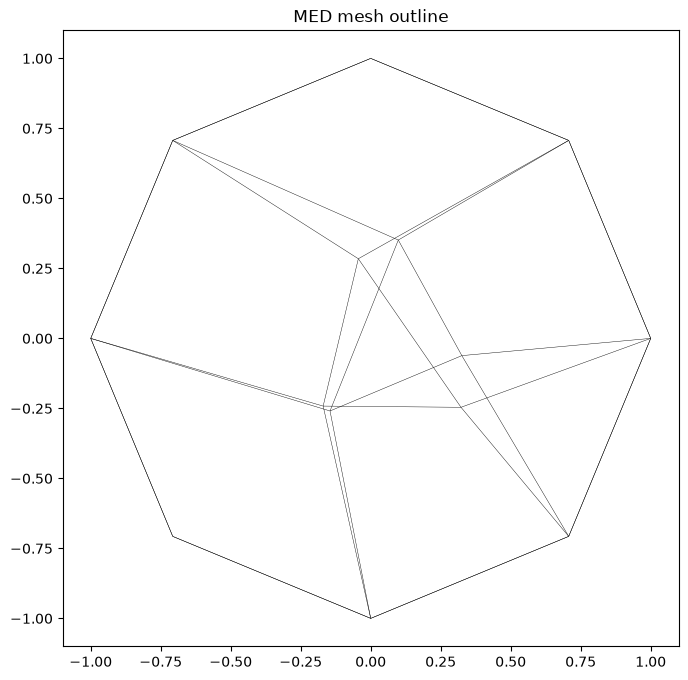

In [7]:
ds.plot_outline()
plt.title("MED mesh outline")


## A derived field: cell area

These engineering files usually carry **no cell data** we can colour by — so we compute one ourselves. `with_variable` attaches `face_areas` as a face-located variable, giving a non-destructive copy of the dataset that `plot` can render as a filled colour map.

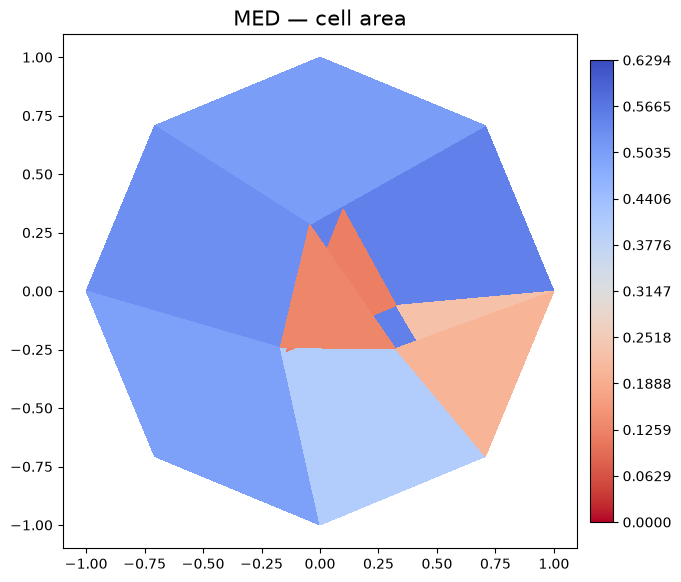

In [8]:
d2 = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True, title="MED — cell area")


The colour map distinguishes the larger quads from the smaller triangular fill cells — a typical Salome surface meshing of a curved boundary.

## Treating the mesh as GIS

Because a `UgridDataset` is just nodes and polygonal faces, pyramids exposes the usual vector-GIS toolbox on it. First, every face as a GeoPandas polygon:

In [9]:
gdf = ds.to_geodataframe()
print(type(gdf).__name__, gdf.shape)
gdf.head()

GeoDataFrame (22, 1)


,geometry
0,"POLYGON ((0.09847 0.35124, 0.32542 -0.06154, 1..."
1,"POLYGON ((-0.70711 0.70711, 0.09847 0.35124, 0..."
2,"POLYGON ((-0.14533 -0.25921, 0.09847 0.35124, ..."
3,"POLYGON ((8.69809e-15 -1, -0.14533 -0.25921, -..."
4,"POLYGON ((0.32542 -0.06154, -0.14533 -0.25921,..."


Being a real `GeoDataFrame`, it plots with GeoPandas directly — a filled view of every element footprint:

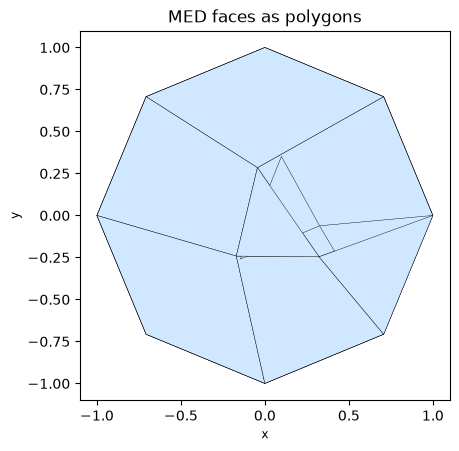

In [10]:
gdf.plot(edgecolor="black", linewidth=0.3, facecolor="#cfe8ff")
plt.title("MED faces as polygons"); plt.gca().set_aspect("equal")


### The outer boundary

`bounding_polygon()` dissolves the faces into the outline of the cross-section.

geometry type: Polygon


Text(0.5, 1.0, 'bounding polygon')

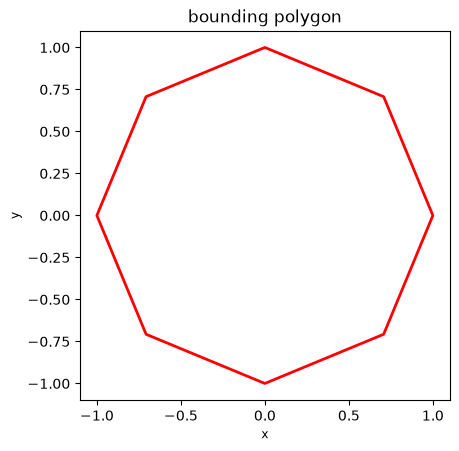

In [11]:
poly = ds.bounding_polygon()
print("geometry type:", poly.geom_type)
gpd.GeoSeries([poly]).plot(facecolor="none", edgecolor="red", linewidth=2)
plt.gca().set_aspect("equal"); plt.title("bounding polygon")

### Cropping to a bounding box

`crop(bbox=...)` returns a new `UgridDataset` with only the faces inside the box — handy for zooming into a region of a large mesh. We crop to the left half of the extent.

faces before / after: 22 -> 9


Text(0.5, 1.0, 'cropped to the left half')

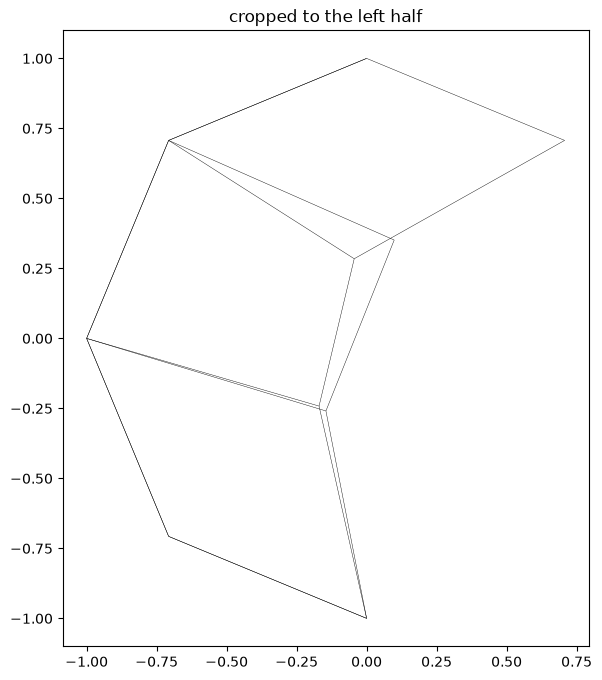

In [12]:
xmin, ymin, xmax, ymax = ds.bounds
half = ds.crop(bbox=(xmin, ymin, (xmin + xmax) / 2, ymax))
print("faces before / after:", ds.n_face, "->", half.n_face)
half.plot_outline(); plt.title("cropped to the left half")

### The face-adjacency graph

`sparse_adjacency()` gives the face-to-face adjacency as a SciPy sparse matrix, and `connected_components()` labels which faces are reachable from which. `plt.spy` shows the sparsity pattern — the fingerprint of how the faces are wired together.

adjacency: (22, 22) nnz = 84
connected components: 1


Text(0.5, 1.0, 'face adjacency')

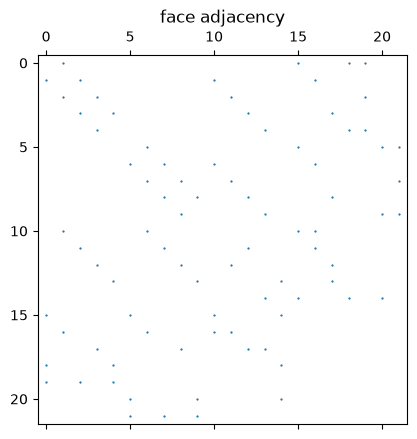

In [13]:
adj = ds.sparse_adjacency()
comp = np.asarray(ds.connected_components())
print("adjacency:", adj.shape, "nnz =", adj.nnz)
print("connected components:", np.unique(comp).size)
plt.spy(adj, markersize=0.6); plt.title("face adjacency")

The surface is one connected patch, so `connected_components` returns a single label; the spy plot shows the irregular but fully-linked adjacency of an unstructured mix of triangles and quads.

### Why circumcenters are skipped here

This is a mixed tri/quad mesh. `circumcenters()` is defined only when **every** face is a triangle, so it raises `ValueError` — we catch it rather than forcing it.

In [14]:
try:
    ds.circumcenters()
except ValueError as e:
    print("skipped (expected):", e)

skipped (expected): circumcenters is only defined for triangular meshes.


### Converting out: xarray and other drivers

`to_xarray()` hands the whole UGRID dataset to xarray (dimensions named the CF-UGRID way), and `to_file(path, driver=...)` re-serialises it through any writer in the driver table — here a round-trip to the `2dm` format in a temp file.

In [15]:
import tempfile
xd = ds.to_xarray()
print("xarray dims:", dict(xd.sizes))
out = Path(tempfile.gettempdir()) / "med_roundtrip.2dm"
ds.to_file(out, driver="2dm")
print("wrote:", out.name, "| exists:", out.exists())

xarray dims: {'mesh2d_scalar': 1, 'mesh2d_nNodes': 33, 'mesh2d_nFaces': 22, 'mesh2d_nMaxFaceNodes': 4}
wrote: med_roundtrip.2dm | exists: True


### What we cannot do here: reprojection & regridding

`to_crs(epsg)` reprojects between coordinate systems — but this mesh has **`crs=None`** (model-local coordinates, no datum), so there is nothing to reproject from; we skip it. Likewise `rasterize_like(...)` and `regrid(...)` map a *data field* onto a raster or another mesh; with no meaningful field and no georeferencing on an engineering mesh they are out of scope. These belong on georeferenced hydrodynamic meshes, not FEM/CFD decks.

## Takeaway

- `driver="med"` reads the Salome/code_aster **HDF5** MED container.
- A mixed triangle+quad surface, geometry-only (`crs=None`), with a `node_z` variable.
- Polygon export, bounding polygon, cropping and the adjacency graph all work; triangle-only `circumcenters` is refused on a mixed mesh.
- No CRS → no reprojection or regridding.